# Figure 13: simulation budget for the noiseless ladder

Section 5.3, `fig:budget`. Negative log-likelihood against the number of
training surfaces over the seventeen-rung noiseless ladder, and the
reconstruction quality the same rungs reach through the full pipeline.

Two departures from the draft figure. The third panel, the
holdout-minus-train gap, is dropped: both NLL curves are on the same
axes in the top panel, so the gap is legible without a panel of its
own. The validation split is dropped from the top panel as well. It
tracks the explicit holdout to within a few hundredths of a nat at
every rung, so the two curves overprint and the plot reads as though
one of them failed to draw. The validation column is still computed and
cached, and the final cell prints both, which is where that agreement
should be read.

The ladder is legacy and its checkpoints predate `starspot_sbi.models`:
bare state dicts for a noiseless architecture that `load_flow` cannot
read. `scripts/ladder.py` is the one place that knows how to load them
and reproduces the training notebook's evaluation conventions exactly,
which is what lets the recomputed holdout NLL be checked against each
rung's recorded value below.

The train-subset NLL was never cached, which is why the legacy render's
middle panel was empty. It is recomputed here from the same pool split
each rung trained on.

## Imports

In [1]:
import sys

from _setup import *

sys.path.insert(0, os.path.join(REPO, 'scripts'))
import ladder

## Setup

The device, the cache, and the ink each series takes.

In [2]:
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CACHE = os.path.join(CACHES, 'fig13_ladder_nll.csv')
# Validation is computed and cached but not drawn: it overprints the holdout.
NLL_SERIES = (('train', 'Train Subset', BLUE, 'o'),
              ('holdout', 'Explicit Holdout', GREEN, 's'))
SSIM_INK = RED
BAND = (0.16, 0.84)        # the percentile band the caption quotes

## Selecting the sample

Every rung of the ladder, and the paired surface sample the SSIM pass
scored at each of them.

In [3]:
R = ladder.rungs()
S = ladder.ladder_ssim()
print(f'{len(R)} rungs, {R.n_surf.min():,} to {R.n_surf.max():,} training '
      f'surfaces')
print(f'SSIM pass: {S.idx.nunique()} holdout surfaces, the same set at every '
      f'rung')

17 rungs, 5,000 to 1,280,000 training surfaces
SSIM pass: 400 holdout surfaces, the same set at every rung


## Inference

The train-subset NLL is the only quantity here that has to be computed:
the validation and holdout columns are recorded per rung. Each rung's
flow is loaded and scored on rows drawn from the surfaces it actually
trained on, one inclination each, matching the holdout convention so
the two curves differ only in which surfaces they cover.

The holdout NLL is recomputed alongside it and checked against the
recorded value. That check is the evidence that the new train column
sits on the same footing as the recorded ones; if it drifts, nothing
below should be believed.

In [4]:
def score_all():
    """Train, validation and holdout NLL for every rung."""
    Zh, Xh = ladder.holdout_rows()
    rows = []
    for _, r in R.iterrows():
        est = ladder.load_rung(r.tag, device=DEVICE)
        h, h_se = ladder.nll_on(est, Zh, Xh, device=DEVICE)
        Zt, Xt = ladder.train_rows(r.n_surf)
        t, t_se = ladder.nll_on(est, Zt, Xt, device=DEVICE)
        rows.append(dict(tag=r.tag, n_surf=int(r.n_surf), train=t,
                         train_se=t_se, n_train_rows=len(Zt),
                         val=float(r.val), holdout=h, holdout_se=h_se,
                         holdout_recorded=float(r.test)))
        del est, Zt, Xt
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()
        print(f'  {r.tag}', flush=True)
    return pd.DataFrame(rows)


os.makedirs(CACHES, exist_ok=True)
# The guard checks the rung set, not just that a file is there, so a ladder
# that gains or loses a rung recomputes instead of being silently reused.
if os.path.exists(CACHE):
    D = pd.read_csv(CACHE)
    if not np.array_equal(D.tag.values, R.tag.values):
        D = score_all()
        D.to_csv(CACHE, index=False)
else:
    D = score_all()                 # seventeen rungs; tens of minutes
    D.to_csv(CACHE, index=False)

drift = (D.holdout - D.holdout_recorded).abs().max()
print(f'{len(D)} rungs scored; worst holdout NLL drift against the recorded '
      f'value {drift:.5f} nats')
if drift > 0.01:
    print('  the evaluation no longer reproduces the ladder; stop here')

17 rungs scored; worst holdout NLL drift against the recorded value 0.00000 nats


## The top-rung slope

The caption asks for the slope the NLL is still falling at where the
paper's budget sits. Taken over the last decade of the ladder, so it
describes the top end rather than the whole curve.

In [5]:
BUDGET = 640000            # the budget the paper trains at

top = D[D.n_surf >= BUDGET / 10]
slope = np.polyfit(np.log10(top.n_surf), top.holdout, 1)[0]
print(f'holdout NLL slope over the last decade ({top.n_surf.min():,} to '
      f'{top.n_surf.max():,}): {slope:.1f} nats per decade')
last = D[D.n_surf >= BUDGET]
slope_top = np.polyfit(np.log10(last.n_surf), last.holdout, 1)[0]
print(f'over the rungs at and above {BUDGET:,}: {slope_top:.1f} nats per '
      f'decade')

holdout NLL slope over the last decade (80,000 to 1,280,000): -26.5 nats per decade
over the rungs at and above 640,000: -10.7 nats per decade


## Plotting

Draws the figure from the names bound above.

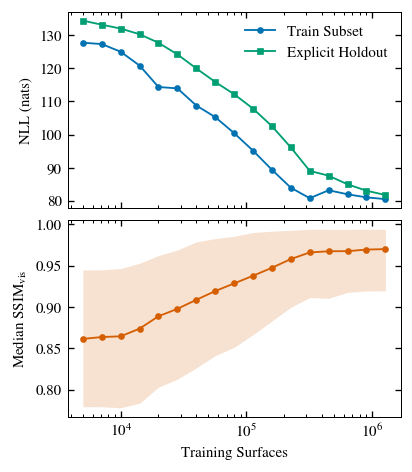

In [6]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(COL, COL * 1.15), sharex=True)

for key, lab, ink, mk in NLL_SERIES:
    ax0.plot(D.n_surf, D[key], color=ink, marker=mk, ms=3, lw=1.1, label=lab)
ax0.set_ylabel('NLL (nats)')
ax0.legend(loc='upper right')

g = S.groupby('n_surf')['ssim']
ax1.plot(g.median().index, g.median().values, color=SSIM_INK, marker='o',
         ms=3, lw=1.1)
ax1.fill_between(g.median().index, g.quantile(BAND[0]).values,
                 g.quantile(BAND[1]).values, color=SSIM_INK, alpha=0.18, lw=0)
ax1.set_ylabel(r'Median ${\rm SSIM}_{\rm vis}$')
ax1.set_xlabel('Training Surfaces')
ax1.set_xscale('log')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 5.3 text and
the caption quote.

In [7]:
save_fig(fig, 'fig13_budget')
q = S.groupby('n_surf')['ssim'].quantile
med = S.groupby('n_surf')['ssim'].median()
print(f'SSIM_vis median {med.iloc[0]:.4f} at {med.index[0]:,} surfaces to '
      f'{med.iloc[-1]:.4f} at {med.index[-1]:,}')
print(f'  band at the top rung: {q(BAND[0]).iloc[-1]:.4f} to '
      f'{q(BAND[1]).iloc[-1]:.4f}')
b = D[D.n_surf == BUDGET].iloc[0]
print(f'NLL at {BUDGET:,}: train {b.train:.2f}, validation {b.val:.2f}, '
      f'holdout {b.holdout:.2f}')
gap = D.holdout - D.train
print(f'holdout minus train gap: {gap.iloc[0]:+.2f} nats at the bottom rung, '
      f'{gap.iloc[-1]:+.2f} at the top')
print(f'  largest gap {gap.max():+.2f} nats at '
      f'{D.n_surf.iloc[int(gap.argmax())]:,} surfaces')
# The reason the validation curve is not drawn: it is the holdout curve.
vh = (D.val - D.holdout).abs()
print(f'validation against holdout: agree to {vh.max():.3f} nats at worst '
      f'({D.tag.iloc[int(vh.argmax())]}), {vh.median():.3f} typical')

wrote notebooks/paper/figs/fig13_budget.pdf, notebooks/paper/figs/fig13_budget.png
SSIM_vis median 0.8614 at 5,000 surfaces to 0.9700 at 1,280,000
  band at the top rung: 0.9195 to 0.9938
NLL at 640,000: train 81.99, validation 84.99, holdout 85.00
holdout minus train gap: +6.66 nats at the bottom rung, +1.24 at the top
  largest gap +13.35 nats at 20,000 surfaces
validation against holdout: agree to 0.473 nats at worst (n40000), 0.212 typical
